# Phase 7: Data Preprocessing

## Student Performance Prediction Using Machine Learning and Explainable AI

### Objectives
- Load the cleaned Mathematics and Portuguese datasets.
- Validate the target variable.
- Separate features and target.
- Split data into training and testing sets.
- Encode categorical features.
- Scale numerical features.
- Prepare data for model training.

**Target:** `performance`  
**Labels:** 0 = At Risk, 1 = Pass  
**Important:** The final grade `G3`, which defines the target, will not be used as an input feature.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
# Detect the project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

DATA_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MATH_PATH = DATA_DIR / "student_mat_clean.csv"
PORT_PATH = DATA_DIR / "student_por_clean.csv"

print("Project root:", PROJECT_ROOT)
print("Processed data directory:", DATA_DIR)
print("Mathematics file exists:", MATH_PATH.exists())
print("Portuguese file exists:", PORT_PATH.exists())

Project root: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction
Processed data directory: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed
Mathematics file exists: True
Portuguese file exists: True


In [7]:
if not MATH_PATH.exists() or not PORT_PATH.exists():
    raise FileNotFoundError(
        "A processed dataset is missing. "
        "Check the filenames inside data/processed."
    )

math_df = pd.read_csv(MATH_PATH)
port_df = pd.read_csv(PORT_PATH)

print("Mathematics dataset shape:", math_df.shape)
print("Portuguese dataset shape:", port_df.shape)

display(math_df.head())
display(port_df.head())

Mathematics dataset shape: (395, 34)
Portuguese dataset shape: (649, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,1


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,1


In [8]:
required_columns = {"G3", "performance"}

for name, df in [
    ("Mathematics", math_df),
    ("Portuguese", port_df)
]:
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{name} dataset is missing {missing_columns}. "
            "Run the target-creation notebook first."
        )

    if df["performance"].isna().any():
        raise ValueError(f"{name} dataset has missing target values.")

    if not set(df["performance"].unique()).issubset({0, 1}):
        raise ValueError(
            f"{name} performance target must contain only 0 and 1."
        )

    # Confirm the target agrees with the defined threshold
    expected_target = (df["G3"] >= 10).astype(int)

    if not df["performance"].equals(expected_target):
        raise ValueError(
            f"{name} target does not match the G3 >= 10 rule."
        )

    print(f"{name}: target validation passed.")

print("\nAll target checks passed.")

Mathematics: target validation passed.
Portuguese: target validation passed.

All target checks passed.


In [9]:
for name, df in [
    ("Mathematics", math_df),
    ("Portuguese", port_df)
]:
    print(f"\n--- {name} dataset ---")
    print("Rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isna().sum().sum())

    missing = df.isna().sum()
    print("\nColumns with missing values:")
    display(missing[missing > 0])


--- Mathematics dataset ---
Rows: 395
Duplicate rows: 0
Missing values: 0

Columns with missing values:


Series([], dtype: int64)


--- Portuguese dataset ---
Rows: 649
Duplicate rows: 0
Missing values: 0

Columns with missing values:


Series([], dtype: int64)


Mathematics target distribution:


,Class,Count,Percentage
0,At Risk (0),130,32.91
1,Pass (1),265,67.09


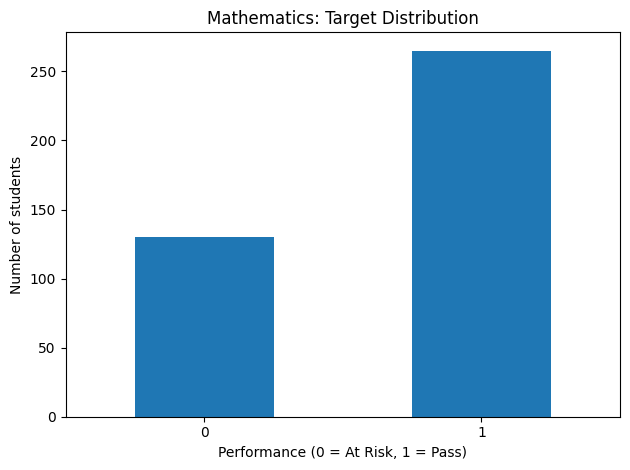


Portuguese target distribution:


,Class,Count,Percentage
0,At Risk (0),100,15.41
1,Pass (1),549,84.59


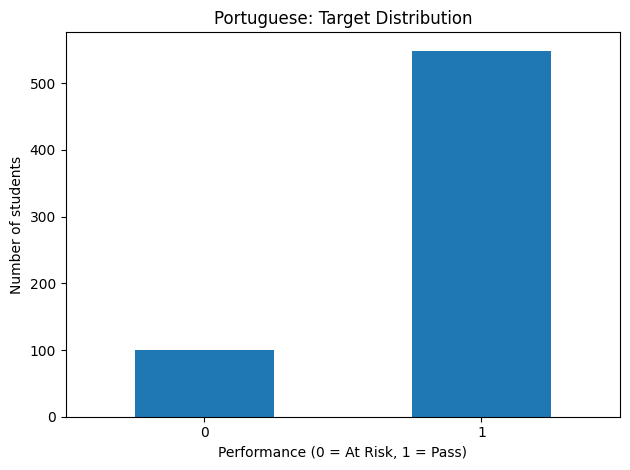

In [10]:
for name, df in [
    ("Mathematics", math_df),
    ("Portuguese", port_df)
]:
    print(f"\n{name} target distribution:")

    counts = df["performance"].value_counts().reindex(
        [0, 1], fill_value=0
    )

    distribution = pd.DataFrame({
        "Class": ["At Risk (0)", "Pass (1)"],
        "Count": counts.values,
        "Percentage": (
            counts.values / len(df) * 100
        ).round(2)
    })

    display(distribution)

    counts.plot(
        kind="bar",
        rot=0,
        title=f"{name}: Target Distribution",
        xlabel="Performance (0 = At Risk, 1 = Pass)",
        ylabel="Number of students"
    )
    plt.tight_layout()
    plt.show()

In [11]:
TARGET = "performance"

def separate_features_target(df, dataset_name):
    # Remove the target and final grade from input features
    X = df.drop(columns=[TARGET, "G3"]).copy()
    y = df[TARGET].astype(int).copy()

    if TARGET in X.columns or "G3" in X.columns:
        raise ValueError("Target leakage detected in input features.")

    if len(X) != len(y):
        raise ValueError("Feature and target row counts do not match.")

    print(f"\n{dataset_name}")
    print("Feature shape:", X.shape)
    print("Target shape:", y.shape)
    print("G3 excluded:", "G3" not in X.columns)
    print("Target excluded from features:", TARGET not in X.columns)

    return X, y

X_math, y_math = separate_features_target(
    math_df, "Mathematics"
)

X_port, y_port = separate_features_target(
    port_df, "Portuguese"
)


Mathematics
Feature shape: (395, 32)
Target shape: (395,)
G3 excluded: True
Target excluded from features: True

Portuguese
Feature shape: (649, 32)
Target shape: (649,)
G3 excluded: True
Target excluded from features: True


In [12]:
def inspect_feature_types(X, dataset_name):
    categorical_features = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    numerical_features = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    print(f"\n{dataset_name}")
    print("Categorical features:", len(categorical_features))
    print(categorical_features)
    print("\nNumerical features:", len(numerical_features))
    print(numerical_features)

    return categorical_features, numerical_features

cat_math, num_math = inspect_feature_types(
    X_math, "Mathematics"
)

cat_port, num_port = inspect_feature_types(
    X_port, "Portuguese"
)


Mathematics
Categorical features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical features: 15
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Portuguese
Categorical features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical features: 15
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [13]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

X_math_train, X_math_test, y_math_train, y_math_test = (
    train_test_split(
        X_math,
        y_math,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_math
    )
)

X_port_train, X_port_test, y_port_train, y_port_test = (
    train_test_split(
        X_port,
        y_port,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_port
    )
)

print("MATHEMATICS")
print("Training:", X_math_train.shape, y_math_train.shape)
print("Testing: ", X_math_test.shape, y_math_test.shape)

print("\nPORTUGUESE")
print("Training:", X_port_train.shape, y_port_train.shape)
print("Testing: ", X_port_test.shape, y_port_test.shape)

assert len(X_math_train) + len(X_math_test) == len(X_math)
assert len(X_port_train) + len(X_port_test) == len(X_port)

print("\nTrain-test split completed.")

MATHEMATICS
Training: (316, 32) (316,)
Testing:  (79, 32) (79,)

PORTUGUESE
Training: (519, 32) (519,)
Testing:  (130, 32) (130,)

Train-test split completed.


In [14]:
def build_preprocessor(categorical_features, numerical_features):
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numerical_features),
            ("categorical", categorical_pipeline, categorical_features)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    return preprocessor

math_preprocessor = build_preprocessor(cat_math, num_math)
port_preprocessor = build_preprocessor(cat_port, num_port)

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


In [15]:
# Mathematics dataset
X_math_train_processed = math_preprocessor.fit_transform(
    X_math_train
)
X_math_test_processed = math_preprocessor.transform(
    X_math_test
)

# Portuguese dataset
X_port_train_processed = port_preprocessor.fit_transform(
    X_port_train
)
X_port_test_processed = port_preprocessor.transform(
    X_port_test
)

print("Mathematics processed training shape:",
      X_math_train_processed.shape)
print("Mathematics processed testing shape:",
      X_math_test_processed.shape)

print("\nPortuguese processed training shape:",
      X_port_train_processed.shape)
print("Portuguese processed testing shape:",
      X_port_test_processed.shape)

print("\nEncoding and scaling completed.")

Mathematics processed training shape: (316, 58)
Mathematics processed testing shape: (79, 58)

Portuguese processed training shape: (519, 58)
Portuguese processed testing shape: (130, 58)

Encoding and scaling completed.


In [16]:
math_feature_names = math_preprocessor.get_feature_names_out()
port_feature_names = port_preprocessor.get_feature_names_out()

print("Mathematics transformed features:")
print(math_feature_names.tolist())

print("\nPortuguese transformed features:")
print(port_feature_names.tolist())

assert X_math_train_processed.shape[1] == len(math_feature_names)
assert X_port_train_processed.shape[1] == len(port_feature_names)

assert np.isfinite(X_math_train_processed).all()
assert np.isfinite(X_math_test_processed).all()
assert np.isfinite(X_port_train_processed).all()
assert np.isfinite(X_port_test_processed).all()

print("\nFeature and numerical checks passed.")

Mathematics transformed features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'school_GP', 'school_MS', 'sex_F', 'sex_M', 'address_R', 'address_U', 'famsize_GT3', 'famsize_LE3', 'Pstatus_A', 'Pstatus_T', 'Mjob_at_home', 'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'Fjob_at_home', 'Fjob_health', 'Fjob_other', 'Fjob_services', 'Fjob_teacher', 'reason_course', 'reason_home', 'reason_other', 'reason_reputation', 'guardian_father', 'guardian_mother', 'guardian_other', 'schoolsup_no', 'schoolsup_yes', 'famsup_no', 'famsup_yes', 'paid_no', 'paid_yes', 'activities_no', 'activities_yes', 'nursery_no', 'nursery_yes', 'higher_no', 'higher_yes', 'internet_no', 'internet_yes', 'romantic_no', 'romantic_yes']

Portuguese transformed features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', '

In [17]:
def compare_class_distributions(y_train, y_test, dataset_name):
    comparison = pd.DataFrame({
        "Training count": y_train.value_counts().reindex(
            [0, 1], fill_value=0
        ),
        "Testing count": y_test.value_counts().reindex(
            [0, 1], fill_value=0
        )
    })

    comparison.index = ["At Risk (0)", "Pass (1)"]

    print(f"\n{dataset_name} class distribution:")
    display(comparison)

compare_class_distributions(
    y_math_train, y_math_test, "Mathematics"
)

compare_class_distributions(
    y_port_train, y_port_test, "Portuguese"
)


Mathematics class distribution:


,Training count,Testing count
At Risk (0),104,26
Pass (1),212,53



Portuguese class distribution:


,Training count,Testing count
At Risk (0),80,20
Pass (1),439,110


In [18]:
import joblib

# Create output directories
MODEL_DIR = PROJECT_ROOT / "models"
PREPARED_DIR = DATA_DIR / "model_ready"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PREPARED_DIR.mkdir(parents=True, exist_ok=True)

def save_prepared_data(
    X_train, X_test, y_train, y_test,
    feature_names, dataset_name
):
    train_df = pd.DataFrame(
        X_train, columns=feature_names
    )
    test_df = pd.DataFrame(
        X_test, columns=feature_names
    )

    train_df[TARGET] = y_train.to_numpy()
    test_df[TARGET] = y_test.to_numpy()

    train_path = PREPARED_DIR / f"{dataset_name}_train.csv"
    test_path = PREPARED_DIR / f"{dataset_name}_test.csv"

    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)

    print("Saved:", train_path)
    print("Saved:", test_path)

save_prepared_data(
    X_math_train_processed,
    X_math_test_processed,
    y_math_train,
    y_math_test,
    math_feature_names,
    "student_mat"
)

save_prepared_data(
    X_port_train_processed,
    X_port_test_processed,
    y_port_train,
    y_port_test,
    port_feature_names,
    "student_por"
)

# Save fitted preprocessing objects for future inference
joblib.dump(
    math_preprocessor,
    MODEL_DIR / "math_preprocessor.joblib"
)

joblib.dump(
    port_preprocessor,
    MODEL_DIR / "port_preprocessor.joblib"
)

print("\nPreprocessed datasets and preprocessors saved.")

Saved: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\model_ready\student_mat_train.csv
Saved: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\model_ready\student_mat_test.csv
Saved: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\model_ready\student_por_train.csv
Saved: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\model_ready\student_por_test.csv

Preprocessed datasets and preprocessors saved.


In [19]:
expected_files = [
    PREPARED_DIR / "student_mat_train.csv",
    PREPARED_DIR / "student_mat_test.csv",
    PREPARED_DIR / "student_por_train.csv",
    PREPARED_DIR / "student_por_test.csv",
    MODEL_DIR / "math_preprocessor.joblib",
    MODEL_DIR / "port_preprocessor.joblib"
]

for path in expected_files:
    print(
        "[OK]" if path.exists() else "[MISSING]",
        path.relative_to(PROJECT_ROOT)
    )
    assert path.exists(), f"Expected output missing: {path}"

# Check that the saved datasets contain the target
for filename in [
    "student_mat_train.csv",
    "student_mat_test.csv",
    "student_por_train.csv",
    "student_por_test.csv"
]:
    saved_df = pd.read_csv(PREPARED_DIR / filename)
    assert TARGET in saved_df.columns
    assert saved_df[TARGET].notna().all()
    assert set(saved_df[TARGET].unique()).issubset({0, 1})

print("\nAll preprocessing checks passed successfully!")

[OK] data\processed\model_ready\student_mat_train.csv
[OK] data\processed\model_ready\student_mat_test.csv
[OK] data\processed\model_ready\student_por_train.csv
[OK] data\processed\model_ready\student_por_test.csv
[OK] models\math_preprocessor.joblib
[OK] models\port_preprocessor.joblib

All preprocessing checks passed successfully!


## Preprocessing Summary

The Mathematics and Portuguese student performance datasets were prepared for machine learning.

The workflow included:
1. Dataset and target validation.
2. Missing-value and duplicate inspection.
3. Separation of input features and target.
4. Exclusion of the final grade G3 to prevent target leakage.
5. Stratified 80:20 training-testing split.
6. Numerical feature scaling.
7. Categorical feature encoding.
8. Fitting preprocessing steps exclusively on training data.
9. Saving prepared datasets and fitted preprocessors.

### Important Note
Class balancing has not yet been applied. Any resampling will be performed on training data only, keeping the test data untouched.

### Next Phase
Feature engineering, class imbalance analysis, and model training preparation.